# 07 Bonus: do transformers (the BERT family) do better?

**Why this notebook.** In the course we met BERT, a **transformer** that reads text. Could it solve our
problem? Not directly: BERT reads **words**, and our inputs are **pixels**. But BERT has two cousins that
read images:

- **ViT** (Vision Transformer): the same architecture as BERT, but the image is cut into 16 x 16 pixel
  squares that play the role of words. We use ViT-B/16 trained on ImageNet, frozen, with our linear head,
  exactly like the ResNet18 of notebook 05.
- **CLIP**: an image encoder trained **together with a text encoder** (a transformer like BERT) on 400
  million images found on the Internet with their captions. Images and sentences end up in the same space,
  so CLIP can classify **without any training** ("zero-shot"): we give it one sentence per style and it
  picks the closest one. We also try it frozen with our linear head.

**Rules of this bonus.** The test set was used once, in notebook 06, to report our chosen model. We do not
reopen it here: every number below is on the **validation** set (219 paintings), with the same split and
the same head recipe as notebook 05. This notebook does not change our recommendation; it says what to try
next.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import os
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from museum_guide.benchmark import cpu_threads, latency_ms
from museum_guide.config import FAST_RUN, set_seed
from museum_guide.data import class_names, load_images, load_metadata, make_split
from museum_guide.evaluation import confusion_matrix, paired_bootstrap, per_class_report, save_results
from museum_guide.features import cached_features
from museum_guide.foundation import CLIPEncoder, ViTEncoder, cached, class_text_embeddings, zero_shot_predict
from museum_guide.models import ResNetClassifier
from museum_guide.plots import PALETTE, plot_confusion, save_figure
from museum_guide.recipes import train_head
from museum_guide.training import evaluate, make_loaders, predict

set_seed()
SEEDS = [0] if FAST_RUN else [0, 1, 2]
loss_fn = nn.CrossEntropyLoss()

meta = load_metadata()
meta["split"] = make_split(meta)
classes = class_names(meta)
trval = meta[meta["split"] != "test"].reset_index(drop=True)  # the test paintings are not even loaded
is_train = torch.tensor((trval["split"] == "train").to_numpy())
is_val = torch.tensor((trval["split"] == "val").to_numpy())
y = torch.tensor(trval["label_idx"].to_numpy())
images = load_images(trval, 224)
print(f"train {int(is_train.sum())} | validation {int(is_val.sum())} | test not loaded | seeds {SEEDS}")

train 1061 | validation 219 | test not loaded | seeds [0, 1, 2]


## 1. Three frozen feature extractors

**What we do.** Each frozen network turns every painting into a vector of numbers, once, saved in
`data/cache`: 512 numbers for ResNet18 (notebook 05), 768 for ViT-B/16, 512 for CLIP. On each vector we
train the same linear head (`train_head`, 3 seeds) and measure the validation accuracy.

In [2]:
resnet_all, _ = cached_features(meta)  # all 1 500 rows, computed in notebook 05
keep = torch.tensor((meta["split"] != "test").to_numpy())
features = {"ResNet18": (resnet_all[keep], None)}
features["ViT-B/16"] = cached("vit_b16", trval, ViTEncoder, images)
features["CLIP ViT-B/32"] = cached("clip_vit_b32", trval, CLIPEncoder, images)

rows, heads = [], {}
for name, (F, seconds) in features.items():
    for seed in SEEDS:
        head, h = train_head(F[is_train], y[is_train], F[is_val], y[is_val], seed=seed)
        val_loss, val_acc = evaluate(head, make_loaders(F[is_train], y[is_train], F[is_val], y[is_val]).val, loss_fn)
        rows.append({"model": f"{name} frozen + linear head", "seed": seed, "features": F.shape[1], "val_acc": val_acc})
        if seed == 0:
            heads[name] = head
probe_runs = pd.DataFrame(rows)
probe_table = probe_runs.groupby("model", sort=False).agg(features=("features", "first"), val_acc=("val_acc", "mean"),
                                                          val_acc_std=("val_acc", "std"))
probe_table.round(3)

,features,val_acc,val_acc_std
model,,,
ResNet18 frozen + linear head,512,0.881,0.000
ViT-B/16 frozen + linear head,768,0.881,0.005
CLIP ViT-B/32 frozen + linear head,512,0.947,0.003


**What we see.**

- **ViT-B/16**, the BERT architecture on image patches, reaches **88.1 %** (standard deviation 0.5), exactly
  like ResNet18 (88.1 %). Being a transformer does not help by itself: what matters is what the network
  learned, and both learned from the same ImageNet photos.
- **CLIP** reaches **94.7 %** (standard deviation 0.3) with the same linear head: 6.6 points more than
  ResNet18. CLIP learned from images **and their captions**, written by people, and captions of paintings
  often name their style.

## 2. CLIP without any training (zero-shot)

**What we do.** CLIP's text encoder turns each sentence into a vector in the same space as the images. We
wrote two sentences per style **once, before looking at any score**, and we never changed them (changing them
after seeing the validation score would be tuning on validation). For each style we average its two sentence
vectors; each painting gets the style whose vector is the closest (cosine similarity). No weight is trained.

CLIP zero-shot validation accuracy: 0.890


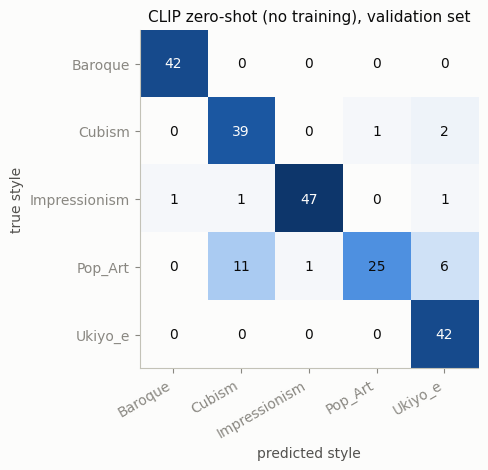

,recall,precision,f1,images
Baroque,1.000,0.977,0.988,42
Cubism,0.929,0.765,0.839,42
Impressionism,0.940,0.979,0.959,50
Pop_Art,0.581,0.962,0.725,43
Ukiyo_e,1.000,0.824,0.903,42


In [3]:
prompts = {
    "Baroque": ["a Baroque painting", "a painting in the Baroque style"],
    "Cubism": ["a Cubist painting", "a painting in the Cubism style"],
    "Impressionism": ["an Impressionist painting", "a painting in the Impressionism style"],
    "Pop_Art": ["a Pop Art painting", "a painting in the Pop Art style"],
    "Ukiyo_e": ["a Ukiyo-e Japanese woodblock print", "a painting in the Ukiyo-e style"],
}
clip = CLIPEncoder()
class_text = class_text_embeddings(clip, prompts, classes)
F_clip = features["CLIP ViT-B/32"][0]
zero_pred = zero_shot_predict(F_clip[is_val], class_text)
zero_acc = (zero_pred == y[is_val]).float().mean().item()
cm = confusion_matrix(y[is_val], zero_pred, len(classes))
print(f"CLIP zero-shot validation accuracy: {zero_acc:.3f}")
plot_confusion(cm, classes, "CLIP zero-shot (no training), validation set", save_as="07_confusion_clip_zero_shot")
per_class_report(cm, classes).round(3)

**What we see.** Without training a single weight, CLIP finds the right style for **89.0 %** of the
validation paintings, the level of our trained ResNet18 + linear head (88.1 %).

- Baroque and Ukiyo-e are always found (100 %), Impressionism 94 %, Cubism 93 %.
- Its weak point is **Pop Art**: only 25 of 43 paintings are found (58 %). It takes 11 of them for Cubism
  and 6 for Ukiyo-e: flat areas of strong colour, hard outlines.

## 3. Is CLIP's lead real? A paired comparison on validation

**What we do.** As in notebook 06, we compare two models **on the same paintings**: the difference of
accuracy on the 219 validation paintings, with a bootstrap interval (5 000 redraws). Seed 0 of each head.

In [4]:
def val_correct(name):
    F = features[name][0]
    logits, labels = predict(heads[name], make_loaders(F[is_val], y[is_val], F[is_val], y[is_val]).val)
    return (logits.argmax(dim=1) == labels).numpy()


zero_correct = (zero_pred == y[is_val]).numpy()
pairs = [("CLIP ViT-B/32 + linear head", val_correct("CLIP ViT-B/32"), "ResNet18 + linear head", val_correct("ResNet18")),
         ("CLIP zero-shot", zero_correct, "ResNet18 + linear head", val_correct("ResNet18")),
         ("ViT-B/16 + linear head", val_correct("ViT-B/16"), "ResNet18 + linear head", val_correct("ResNet18"))]
paired = pd.DataFrame([{"A": a, "B": b, **paired_bootstrap(ca, cb)} for a, ca, b, cb in pairs])
paired.round(3)

,A,B,diff,ci_low,ci_high,share_not_better
0,CLIP ViT-B/32 + linear head,ResNet18 + linear head,0.068,0.023,0.114,0.001
1,CLIP zero-shot,ResNet18 + linear head,0.009,-0.050,0.068,0.413
2,ViT-B/16 + linear head,ResNet18 + linear head,0.005,-0.046,0.059,0.474


**What we see.**

- **CLIP + linear head against ResNet18 + linear head: +6.8 points** on the same 219 paintings, interval
  2.3 to 11.4 points. In only 0.1 % of the redraws is CLIP not better: on our validation set, the lead is real.
- CLIP zero-shot against ResNet18: +0.9 points, interval -5.0 to +6.8: the same level.
- ViT-B/16 against ResNet18: +0.5 points, interval -4.6 to +5.9: the same level.

## 4. The price on a kiosk CPU

**What we do.** The same measure as notebook 06: one photo at a time (224 x 224), from the pixels to the
predicted style, median of 20 runs, with 1 and 4 CPU threads, and the number of parameters of the network.

In [5]:
class EncoderWithHead(nn.Module):
    def __init__(self, encoder, head):
        super().__init__()
        self.encoder, self.head = encoder, head

    def forward(self, x):
        return self.head(self.encoder(x))


kiosk_models = {"ResNet18 + linear head": ResNetClassifier(train_from=None, head=heads["ResNet18"]).eval(),
                "ViT-B/16 + linear head": EncoderWithHead(ViTEncoder(), heads["ViT-B/16"]).eval(),
                "CLIP ViT-B/32 + linear head": EncoderWithHead(clip, heads["CLIP ViT-B/32"]).eval()}
photos = [images[is_val][i:i + 1] for i in range(20)]
speed = []
with torch.no_grad():
    for name, model in kiosk_models.items():
        row = {"model": name, "parameters_millions": sum(p.numel() for p in model.parameters()) / 1e6}
        for n in (1, 4):
            with cpu_threads(n):
                row[f"ms_{n}_thread"] = latency_ms(model, photos, warmup=3, runs=20)["median_ms"]
        speed.append(row)
speed_table = pd.DataFrame(speed).set_index("model")
speed_table.round(1)

,parameters_millions,ms_1_thread,ms_4_thread
model,,,
ResNet18 + linear head,11.2,38.2,12.8
ViT-B/16 + linear head,85.8,349.4,126.0
CLIP ViT-B/32 + linear head,151.3,104.9,45.9


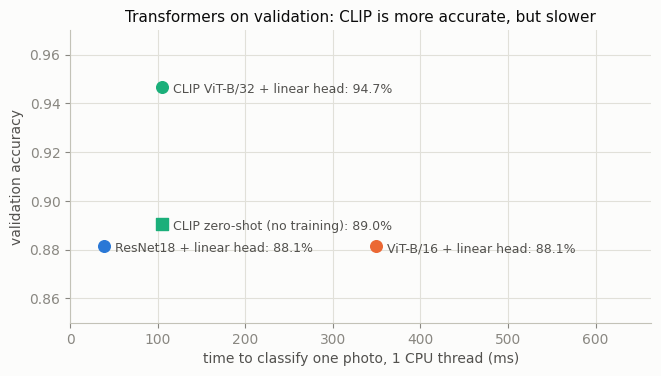

In [6]:
summary = pd.DataFrame({
    "val_acc": [probe_table.loc["ResNet18 frozen + linear head", "val_acc"], probe_table.loc["ViT-B/16 frozen + linear head", "val_acc"],
                zero_acc, probe_table.loc["CLIP ViT-B/32 frozen + linear head", "val_acc"]],
    "ms_1_thread": [speed_table.loc["ResNet18 + linear head", "ms_1_thread"], speed_table.loc["ViT-B/16 + linear head", "ms_1_thread"],
                    speed_table.loc["CLIP ViT-B/32 + linear head", "ms_1_thread"], speed_table.loc["CLIP ViT-B/32 + linear head", "ms_1_thread"]],
}, index=["ResNet18 + linear head", "ViT-B/16 + linear head", "CLIP zero-shot (no training)", "CLIP ViT-B/32 + linear head"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = [PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[2]]
for (name, r), color, marker in zip(summary.iterrows(), colors, ["o", "o", "s", "o"]):
    ax.scatter(r["ms_1_thread"], r["val_acc"], s=70, color=color, marker=marker, zorder=3)
    ax.annotate(f"{name}: {r['val_acc']:.1%}", (r["ms_1_thread"], r["val_acc"]), xytext=(8, -4), textcoords="offset points",
                fontsize=9, color="#52514e")
ax.set_xlim(0, summary["ms_1_thread"].max() * 1.9)
ax.set_ylim(0.85, 0.97)
ax.set_xlabel("time to classify one photo, 1 CPU thread (ms)")
ax.set_ylabel("validation accuracy")
ax.set_title("Transformers on validation: CLIP is more accurate, but slower")
save_figure(fig, "07_transformers_accuracy_vs_speed")
plt.show()

**What we see.**

- **Time per photo, one CPU thread, in this run**: 38 ms for ResNet18, 105 ms for CLIP (2.7 times more) and
  349 ms for ViT-B/16 (9 times more). With 4 threads: 13, 46 and 126 ms. Times move by about 30 % from
  one run to another on a laptop: notebook 06 measured 53 ms for ResNet18. The ratios are what to remember.
- **Size**: 11 million parameters for ResNet18, 86 million for ViT-B/16. CLIP counts 151 million with its text
  part; the kiosk only needs its image part (about 88 million).
- CLIP stays well under a second per photo, but it is a bigger and slower model to run and to update.

In [7]:
save_results("07_transformers", {
    "probe_runs": probe_runs.to_dict(orient="records"),
    "probe_table": probe_table.reset_index().to_dict(orient="records"),
    "clip_zero_shot": {"val_acc": zero_acc, "prompts": prompts,
                       "per_class": per_class_report(cm, classes).reset_index(names="style").to_dict(orient="records")},
    "paired_validation": paired.to_dict(orient="records"),
    "speed": speed_table.reset_index().to_dict(orient="records"),
    "feature_seconds_per_image_batch32": {k: v[1] for k, v in features.items() if v[1] is not None},
})

WindowsPath('C:/Users/benca/OneDrive - Thelio/Documents/Perso/Albert School/Deep learning/neural-network-project/reports/results/07_transformers.json')

## What we learned

- **BERT itself cannot classify paintings**: it reads text. Its image version, **ViT-B/16**, is as accurate as
  ResNet18 here (88.1 %) and 9 times slower: no gain for the kiosk.
- **CLIP**, trained on 400 million images with their captions, is the most accurate: **89.0 % without any
  training**, and **94.7 % with our linear head** (+6.8 points over ResNet18, interval 2.3 to 11.4), for
  about 2.7 times the time per photo.
- **Three cautions** before we change the recommendation:
    1. CLIP was trained on images from the Internet, and it has very probably seen WikiArt paintings with
       captions that name their style: part of its score may be memory. The museum's own photos would tell.
    2. These are validation numbers: we did not reopen the test set, which was used once in notebook 06.
    3. It is a bigger model to store and to update (151 million parameters with its text part).
- So our recommendation (frozen ResNet18 + linear head, chosen before the test) stands, and **CLIP is our
  first next step**: test it on a fresh set of real kiosk photos. As a bonus, CLIP also links sentences to
  images, so the same model could answer visitors' questions such as "Which painting shows a stormy sea?"
  (part 2 of the brief).